# Model training with MLflow

Compare persistence, Ridge, and LightGBM using expanding annual validation; reserve 2026 for the final test.

In [1]:
START_DATE = "2022-01-01"
END_DATE = "2026-10-18"
INPUT_FILE = f"data/processed/dataset_{START_DATE}_{END_DATE}.parquet"
TRACKING_URI = "http://127.0.0.1:5001"
EXPERIMENT = "solar-forecasting"
SEED = 42

In [2]:
from hashlib import sha256
from pathlib import Path

import lightgbm
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from lightgbm import LGBMRegressor
from mlflow import sklearn as mlflow_sklearn
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent
DATA_PATH = ROOT / INPUT_FILE
plt.rcParams.update({"figure.figsize": (13, 4), "axes.grid": True})

## Load and validate the training table

In [3]:
dataset = pd.read_parquet(DATA_PATH).sort_values("timestamp_utc").reset_index(drop=True)
dataset["timestamp_utc"] = pd.to_datetime(dataset.timestamp_utc, utc=True).dt.as_unit(
    "ns"
)
TARGET = "target_solar_capacity_factor"
FEATURES = [
    column
    for column in dataset.select_dtypes(include="number").columns
    if not column.startswith("target_")
]
hours = pd.date_range(
    START_DATE,
    pd.Timestamp(END_DATE) + pd.Timedelta(days=1),
    freq="h",
    inclusive="left",
    tz="UTC",
).as_unit("ns")
assert pd.DatetimeIndex(dataset.timestamp_utc).equals(hours)
assert dataset[TARGET].between(0, 1).all()
assert dataset.installed_pv_capacity_mw.gt(0).all()
assert np.isfinite(
    dataset[[*FEATURES, TARGET, "target_solar_generation_mw"]].to_numpy()
).all()
DATA_HASH = sha256(DATA_PATH.read_bytes()).hexdigest()
print(f"Rows: {len(dataset):,}; features: {len(FEATURES)}")

Rows: 42,048; features: 33


## Define baseline forecasts

Persistence uses observations from 24 hours earlier. This simulates hourly forecast origins with available previous-day observations, not a fixed day-ahead batch or a reporting delay. No target lags enter Ridge or LightGBM.

In [4]:
dataset["persistence_mw"] = dataset.target_solar_generation_mw.shift(24)
dataset["persistence_cf"] = dataset[TARGET].shift(24) * dataset.installed_pv_capacity_mw

## Define annual validation folds

Each model is fitted once per fold. Validation covers a complete year without shuffling. No 2026 rows participate in selection. Forecast issue times and historical capacity limitations still require a separate audit.

In [5]:
FOLDS = [2023, 2024, 2025]
splits = pd.DataFrame(
    {
        "validation_year": FOLDS,
        "train_start": [START_DATE] * len(FOLDS),
        "train_end_exclusive": [f"{year}-01-01" for year in FOLDS],
        "validation_end_exclusive": [f"{year + 1}-01-01" for year in FOLDS],
    }
)
display(splits)

,validation_year,train_start,train_end_exclusive,validation_end_exclusive
0,2023,2022-01-01,2023-01-01,2024-01-01
1,2024,2022-01-01,2024-01-01,2025-01-01
2,2025,2022-01-01,2025-01-01,2026-01-01


## Connect to MLflow

Start the tracking server before this cell. Each execution creates a parent run; individual evaluations are nested runs.

In [13]:
mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_experiment(EXPERIMENT)
DEPENDENCIES = [
    f"mlflow=={mlflow.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"lightgbm=={lightgbm.__version__}",
    f"pandas=={pd.__version__}",
    f"numpy=={np.__version__}",
]

2026/10/19 07:02:29 INFO mlflow.tracking.fluent: Experiment with name 'solar-forecasting' does not exist. Creating a new experiment.


## Metrics and artifacts

Evaluate in MW. WAPE is a percentage; positive bias means overprediction. Daylight uses the saved solar-elevation flag. Preserve raw predictions without clipping or forcing night-time zeros.

In [7]:
def metrics(frame):
    error = frame.prediction_mw - frame.actual_mw
    return {
        "mae_mw": float(error.abs().mean()),
        "rmse_mw": float(np.sqrt((error**2).mean())),
        "wape_percent": float(100 * error.abs().sum() / frame.actual_mw.abs().sum()),
        "bias_mw": float(error.mean()),
    }


def evaluate(config, year, window="all", stage="validation"):
    boundary = pd.Timestamp(f"{year}-01-01", tz="UTC")
    train_start = (
        pd.Timestamp(START_DATE, tz="UTC")
        if window == "all"
        else boundary - pd.DateOffset(years=1)
    )
    train = dataset.loc[
        dataset.timestamp_utc.ge(train_start) & dataset.timestamp_utc.lt(boundary)
    ]
    valid = dataset.loc[
        dataset.timestamp_utc.ge(boundary)
        & dataset.timestamp_utc.lt(boundary + pd.DateOffset(years=1))
    ]
    assert not train.empty and not valid.empty
    assert train.timestamp_utc.max() < valid.timestamp_utc.min()
    name = config["name"]
    with mlflow.start_run(run_name=f"{name}_{window}_{year}", nested=True) as run:
        mlflow.log_params(
            {
                **config,
                "window": window,
                "stage": stage,
                "evaluation_year": year,
                "train_start": str(train.timestamp_utc.min()),
                "train_end": str(train.timestamp_utc.max()),
                "evaluation_start": str(valid.timestamp_utc.min()),
                "evaluation_end": str(valid.timestamp_utc.max()),
                "train_rows": len(train),
                "evaluation_rows": len(valid),
                "dataset_sha256": DATA_HASH,
                "seed": SEED,
            }
        )
        mlflow.log_dict({"features": FEATURES, "target": TARGET}, "features.json")
        model_uri = ""
        if config["kind"] == "persistence":
            prediction = valid[config["column"]].to_numpy()
        else:
            if config["kind"] == "ridge":
                model = make_pipeline(StandardScaler(), Ridge(alpha=config["alpha"]))
            else:
                model = LGBMRegressor(
                    num_leaves=config["num_leaves"],
                    min_child_samples=config["min_child_samples"],
                    n_estimators=400,
                    learning_rate=0.05,
                    random_state=SEED,
                    n_jobs=2,
                    verbosity=-1,
                    deterministic=True,
                    force_col_wise=True,
                )
                mlflow.log_params({"n_estimators": 400, "learning_rate": 0.05})
            model.fit(train[FEATURES], train[TARGET])
            prediction = (
                np.asarray(model.predict(valid[FEATURES]))
                * valid.installed_pv_capacity_mw.to_numpy()
            )
            info = mlflow_sklearn.log_model(
                model,
                name="model",
                serialization_format="cloudpickle",
                input_example=train[FEATURES].head(5),
                pip_requirements=DEPENDENCIES,
            )
            model_uri = info.model_uri
        assert np.isfinite(prediction).all()
        predictions = pd.DataFrame(
            {
                "timestamp_utc": valid.timestamp_utc.to_numpy(),
                "actual_mw": valid.target_solar_generation_mw.to_numpy(),
                "prediction_mw": prediction,
                "is_daylight": valid.solar_elevation_max.gt(0).to_numpy(),
            }
        )
        predictions["error_mw"] = predictions.prediction_mw - predictions.actual_mw
        scores = metrics(predictions)
        mlflow.log_metrics({f"{stage}_{key}": value for key, value in scores.items()})
        day_scores = metrics(predictions.loc[predictions.is_daylight])
        mlflow.log_metrics(
            {f"{stage}_day_{key}": value for key, value in day_scores.items()}
        )
        for month, frame in predictions.groupby(predictions.timestamp_utc.dt.month):
            month_scores = metrics(frame)
            mlflow.log_metrics(
                {
                    f"{stage}_month_{month:02d}_{key}": value
                    for key, value in month_scores.items()
                }
            )
        mlflow.log_text(predictions.to_csv(index=False), "predictions.csv")
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))
        predictions.head(168).plot(
            x="timestamp_utc", y=["actual_mw", "prediction_mw"], ax=axes[0]
        )
        axes[0].set_ylabel("MW")
        axes[0].set_title("First evaluation week")
        axes[1].hist(predictions.error_mw, bins=60)
        axes[1].set_xlabel("Prediction minus actual, MW")
        axes[1].set_title("Hourly errors")
        fig.tight_layout()
        mlflow.log_figure(fig, "evaluation.png")
        plt.close(fig)
        return {
            "name": name,
            "year": year,
            "window": window,
            "run_id": run.info.run_id,
            "model_uri": model_uri,
            **scores,
        }

## Define nine candidate configurations

Use the same 33 input features across learned models. Tree count and learning rate are fixed; no early stopping or parameter selection uses the final test.

In [8]:
CONFIGS = [
    {"name": "persistence_mw", "kind": "persistence", "column": "persistence_mw"},
    {"name": "persistence_cf", "kind": "persistence", "column": "persistence_cf"},
    *[
        {"name": f"ridge_{alpha}", "kind": "ridge", "alpha": alpha}
        for alpha in [0.1, 10.0, 1000.0]
    ],
    *[
        {
            "name": f"lightgbm_{leaves}_{minimum}",
            "kind": "lightgbm",
            "num_leaves": leaves,
            "min_child_samples": minimum,
        }
        for leaves in [15, 31]
        for minimum in [50, 200]
    ],
]
pd.DataFrame(CONFIGS)

,name,kind,column,alpha,num_leaves,min_child_samples
0,persistence_mw,persistence,persistence_mw,NaN,NaN,NaN
1,persistence_cf,persistence,persistence_cf,NaN,NaN,NaN
2,ridge_0.1,ridge,NaN,0.1,NaN,NaN
3,ridge_10.0,ridge,NaN,10.0,NaN,NaN
4,ridge_1000.0,ridge,NaN,1000.0,NaN,NaN
5,lightgbm_15_50,lightgbm,NaN,NaN,15.0,50.0
6,lightgbm_15_200,lightgbm,NaN,NaN,15.0,200.0
7,lightgbm_31_50,lightgbm,NaN,NaN,31.0,50.0
8,lightgbm_31_200,lightgbm,NaN,NaN,31.0,200.0


## Run 27 validation evaluations

Save the input hash, feature contract, notebook, and environment with the experiment. Fold models predict capacity factor; their outputs must be multiplied by capacity to obtain MW.

In [14]:
with mlflow.start_run(run_name="annual_candidate_comparison") as parent:
    mlflow.log_params({"dataset_sha256": DATA_HASH, "input_file": INPUT_FILE})
    mlflow.log_artifact(str(ROOT / "experiments" / "04_training.ipynb"))
    mlflow.log_dict({"features": FEATURES, "target": TARGET}, "features.json")
    mlflow.log_text("\n".join(DEPENDENCIES), "requirements.txt")
    results = pd.DataFrame(
        [evaluate(config, year) for config in CONFIGS for year in FOLDS]
    )
    mlflow.log_table(results, "validation_results.json")
    COMPARISON_RUN_ID = parent.info.run_id

🏃 View run persistence_mw_all_2023 at: http://127.0.0.1:5001/#/experiments/3/runs/a612e6a85513411a9f0b28b2158f9e40
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3
🏃 View run persistence_mw_all_2024 at: http://127.0.0.1:5001/#/experiments/3/runs/b1d77dcf8e3946778ee1dcf1a27ea66f
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3
🏃 View run persistence_mw_all_2025 at: http://127.0.0.1:5001/#/experiments/3/runs/6b85c5af75694fb9863539627cf5c9bb
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3
🏃 View run persistence_cf_all_2023 at: http://127.0.0.1:5001/#/experiments/3/runs/9435ae7f557c49a9b6d41390edfa9d0e
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3
🏃 View run persistence_cf_all_2024 at: http://127.0.0.1:5001/#/experiments/3/runs/a0035d6caf37475c8f3cdc9ea11c0c27
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


2026/10/19 07:02:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run persistence_cf_all_2025 at: http://127.0.0.1:5001/#/experiments/3/runs/4ca5ed0c93af42ad839886e82ce4d6e4
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


/Users/denys/Projects/Academic/masters-thesis/.venv/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/19 07:02:37 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.
2026/10/19 07:02:38 WARNING ml

🏃 View run ridge_0.1_all_2023 at: http://127.0.0.1:5001/#/experiments/3/runs/2f393eeb0abd40ae96732499688e0657
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


...

🏃 View run lightgbm_31_200_all_2023 at: http://127.0.0.1:5001/#/experiments/3/runs/b0ea21ea83b74c2283bd83dc899767e3
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


2026/10/19 07:02:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
/Users/denys/Projects/Academic/masters-thesis/.venv/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these column

🏃 View run lightgbm_31_200_all_2024 at: http://127.0.0.1:5001/#/experiments/3/runs/c93ef9d55de249c49032954532bf5b3f
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


2026/10/19 07:02:55 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
/Users/denys/Projects/Academic/masters-thesis/.venv/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these column

🏃 View run lightgbm_31_200_all_2025 at: http://127.0.0.1:5001/#/experiments/3/runs/0ed28a384929447b8b4479c43ad54f00
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3
🏃 View run annual_candidate_comparison at: http://127.0.0.1:5001/#/experiments/3/runs/db751e4d5f0641659d42c62cd7074749
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


,mean_wape,worst_year_wape,mean_mae_mw,mean_bias_mw
name,,,,
lightgbm_15_50,11.351037,11.900662,833.410908,352.554022
lightgbm_31_50,11.505569,11.656676,841.323478,384.573698
lightgbm_15_200,11.545251,12.097467,845.923233,367.999057
lightgbm_31_200,11.565333,12.127483,847.923811,399.102780
persistence_mw,22.739254,24.243563,1655.601789,-0.355895
persistence_cf,22.744460,24.248418,1655.979856,3.176657
ridge_1000.0,27.751421,28.506166,2032.848012,300.527146
ridge_10.0,33.665821,49.248670,2392.434162,1276.013956
ridge_0.1,39.294209,68.089812,2740.391709,1688.275734


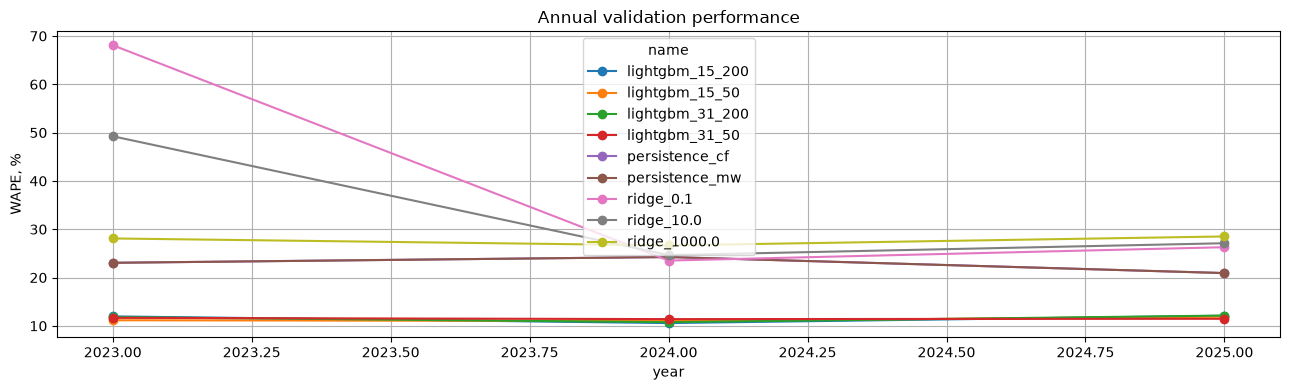

In [15]:
summary = (
    results.groupby("name")
    .agg(
        mean_wape=("wape_percent", "mean"),
        worst_year_wape=("wape_percent", "max"),
        mean_mae_mw=("mae_mw", "mean"),
        mean_bias_mw=("bias_mw", "mean"),
    )
    .sort_values("mean_wape")
)
display(summary)
results.pivot(index="year", columns="name", values="wape_percent").plot(
    marker="o", ylabel="WAPE, %", title="Annual validation performance"
)
plt.tight_layout()
plt.show()

## Compare training-history windows

For the best learned configuration, compare all history against the preceding 12 months on 2024 and 2025. Inspect baseline results before accepting a learned model. This is exploratory selection, not an unbiased final score.

In [16]:
learned_names = [
    config["name"] for config in CONFIGS if config["kind"] != "persistence"
]
BEST_NAME = summary.loc[summary.index.isin(learned_names)].index[0]
BEST_CONFIG = next(config for config in CONFIGS if config["name"] == BEST_NAME)
with mlflow.start_run(run_name=f"history_comparison_{BEST_NAME}"):
    mlflow.set_tag("candidate_comparison_run_id", COMPARISON_RUN_ID)
    history_results = pd.DataFrame(
        [
            evaluate(BEST_CONFIG, year, window)
            for window in ["all", "12_months"]
            for year in [2024, 2025]
        ]
    )
    mlflow.log_table(history_results, "history_results.json")
history_summary = history_results.groupby("window").wape_percent.mean().sort_values()
BEST_WINDOW = history_summary.index[0]
display(history_results)
display(history_summary)

2026/10/19 07:05:05 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
/Users/denys/Projects/Academic/masters-thesis/.venv/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these column

🏃 View run lightgbm_15_50_all_2024 at: http://127.0.0.1:5001/#/experiments/3/runs/4301c4a4367e45fb8dde325d690c4b21
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


2026/10/19 07:05:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
/Users/denys/Projects/Academic/masters-thesis/.venv/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these column

🏃 View run lightgbm_15_50_all_2025 at: http://127.0.0.1:5001/#/experiments/3/runs/9a61473875fe440fbff66c8840874b9d
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


2026/10/19 07:05:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
/Users/denys/Projects/Academic/masters-thesis/.venv/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these column

🏃 View run lightgbm_15_50_12_months_2024 at: http://127.0.0.1:5001/#/experiments/3/runs/d571cb290191424e9ddfa78e299c32aa
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


2026/10/19 07:05:08 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
/Users/denys/Projects/Academic/masters-thesis/.venv/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these column

🏃 View run lightgbm_15_50_12_months_2025 at: http://127.0.0.1:5001/#/experiments/3/runs/374772f7dc4e46cd981c5131989d9b61
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3
🏃 View run history_comparison_lightgbm_15_50 at: http://127.0.0.1:5001/#/experiments/3/runs/d38b616482c9430f8970c7c49449a8a6
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


,name,year,window,run_id,model_uri,mae_mw,rmse_mw,wape_percent,bias_mw
0,lightgbm_15_50,2024,all,4301c4a4367e45fb8dde325d690c4b21,models:/m-a4b1c43bec834e849c4b2125495d936e,790.216837,1505.513986,10.991981,328.841671
1,lightgbm_15_50,2025,all,9a61473875fe440fbff66c8840874b9d,models:/m-97fbe60ab02e41af8aed8b5e113d7848,1002.370442,1926.483556,11.900662,609.653750
2,lightgbm_15_50,2024,12_months,d571cb290191424e9ddfa78e299c32aa,models:/m-0253e7052e19441a91dc80facae360d1,771.435935,1484.915227,10.730738,237.090092
3,lightgbm_15_50,2025,12_months,374772f7dc4e46cd981c5131989d9b61,models:/m-c8dc1733c66648e6961018c7d7e91167,955.980124,1811.173691,11.349892,512.985955


window
12_months    11.040315
all          11.446322
Name: wape_percent, dtype: float64

## Final test: 2026

Run after freezing the model configuration and training window. Refit using only pre-2026 data. Evaluate both baselines for context; do not tune using these results. The partial year does not represent a full annual test. No registry alias is changed.

In [17]:
with mlflow.start_run(run_name="final_2026_test") as parent:
    mlflow.set_tag("candidate_comparison_run_id", COMPARISON_RUN_ID)
    final_model = evaluate(BEST_CONFIG, 2026, BEST_WINDOW, stage="test")
    final_baselines = [
        evaluate(config, 2026, stage="test")
        for config in CONFIGS
        if config["kind"] == "persistence"
    ]
    test_results = pd.DataFrame([final_model, *final_baselines])
    mlflow.log_table(test_results, "test_results.json")
    mlflow.log_dict(
        {
            "config": BEST_CONFIG,
            "window": BEST_WINDOW,
            "model_uri": final_model["model_uri"],
        },
        "selected_model.json",
    )
display(test_results)
print("Model URI for the explainability notebook:", final_model["model_uri"])

2026/10/19 07:05:34 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
/Users/denys/Projects/Academic/masters-thesis/.venv/lib/python3.13/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these column

🏃 View run lightgbm_15_50_12_months_2026 at: http://127.0.0.1:5001/#/experiments/3/runs/e26b009c294b4adb9521ab46d85955e4
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3
🏃 View run persistence_mw_all_2026 at: http://127.0.0.1:5001/#/experiments/3/runs/d5c37753927f48eaafb3bc0df407b743
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3
🏃 View run persistence_cf_all_2026 at: http://127.0.0.1:5001/#/experiments/3/runs/da6f29a441ce4521a9a56bc29ca2bdfc
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3
🏃 View run final_2026_test at: http://127.0.0.1:5001/#/experiments/3/runs/785e43f2aba44dcfad944374535b7718
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/3


,name,year,window,run_id,model_uri,mae_mw,rmse_mw,wape_percent,bias_mw
0,lightgbm_15_50,2026,12_months,e26b009c294b4adb9521ab46d85955e4,models:/m-0eed3692206b4f9d8b3d82ac6dcca89c,983.461142,1744.750212,8.619149,127.965501
1,persistence_mw,2026,all,d5c37753927f48eaafb3bc0df407b743,,2281.648952,4664.021519,19.996593,-3.059834
2,persistence_cf,2026,all,da6f29a441ce4521a9a56bc29ca2bdfc,,2281.808496,4664.655864,19.997991,1.167356


Model URI for the explainability notebook: models:/m-0eed3692206b4f9d8b3d82ac6dcca89c


The logged model accepts the ordered numeric feature table and predicts capacity factor. Data collection, feature generation, and conversion to MW remain outside this model. Register it only after confirming that contract with inference.